# 01 · Traffic and head-of-line blocking: single vs dual endpoint

The KV traffic a request creates, the queueing model that says why one shared queue hurts small messages, and the measured hot-class latency under a cold bulk stream, one endpoint vs two, on native libibverbs and libfabric.

**README sections covered:** [1. What moves: network and storage](../docs/explained/01-traffic.md), [2. Head-of-line blocking](../docs/explained/02-head-of-line-blocking.md)

Figures are written to `docs/figures/` (model figures: arithmetic, proofs and repo results) and `docs/figures/<MODE>/` (measured on the machine that ran the notebook).

In [1]:
MODE = "local"            # "local": smoke runs on this machine (tcp / tcp;ofi_rxm / shm providers)
                          # "cluster": this host is the client, the server runs on PEER over ssh
PEER = "server1"         # ssh host for the server side (cluster mode)
PEER_IP = "192.168.1.242" # server address on the RDMA netdev; default taken from benchmark_dual_qp_remote.py, check it
REMOTE_REPO = None        # repo path on PEER if it differs from this host
DOMAIN = "rxe0"           # RDMA device / libfabric domain on both nodes
SV_GID_INDEX = None       # set if the auto-picked GID (first IPv4-mapped) is wrong, e.g. "1"
HOT_CPU = None            # pin the hot loop (cluster: pick a core away from the NIC IRQs)
COLD_CPU = None           # pin the cold stream thread
ITERS = None              # None: 2000 local, 20000 cluster
RESULTS_SUBDIR = "fabric"


In [2]:
import os, sys, json, socket, subprocess, time
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "middleware").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
HOST = socket.gethostname()
STAMP = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime())
RESULTS = (ROOT / "benchmarks" / "results" / RESULTS_SUBDIR) if MODE == "cluster" else Path("/tmp/scuffed-local") / RESULTS_SUBDIR
RESULTS.mkdir(parents=True, exist_ok=True)
FIGDIR = ROOT / "docs" / "figures"
(FIGDIR / MODE).mkdir(parents=True, exist_ok=True)

import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.4,
    "lines.markersize": 4, "figure.constrained_layout.use": False})
C = {"hot": "#f97316", "cold": "#38bdf8", "spill": "#a78bfa", "ok": "#34d399", "bad": "#f43f5e",
     "gold": "#facc15", "ink": "#1f2937", "muted": "#94a3b8"}

def fig(name, model=False, caption=None, f=None):
    """Save the current figure as PNG + PDF and show it.
    model=True: arithmetic or repo results, same on every machine -> docs/figures/<name>
    model=False: measured on this machine -> docs/figures/<MODE>/<name>"""
    f = f or plt.gcf()
    d = FIGDIR if model else FIGDIR / MODE
    f.tight_layout()
    for ext in ("png", "pdf"):
        f.savefig(d / f"{name}.{ext}", bbox_inches="tight")
    print(f"figure -> {d.relative_to(ROOT)}/{name}.png" + (f"  |  {caption}" if caption else ""))
    plt.show()

def save(name, obj):
    p = RESULTS / f"{HOST}_{name}.json"
    obj = {"host": HOST, "utc": STAMP, "mode": MODE, **obj}
    p.write_text(json.dumps(obj, indent=2, default=str))
    print("wrote", p)
    return p

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, cwd=ROOT)
    print(r.stdout[-4000:], r.stderr[-2000:])
    if check and r.returncode:
        raise RuntimeError(f"{cmd} -> {r.returncode}")
    return r
print("repo:", ROOT, "| host:", HOST, "| mode:", MODE, "| results ->", RESULTS, "| figures ->", FIGDIR)

repo: /home/claude/scuffedrdma | host: vm | mode: local | results -> /tmp/scuffed-local/fabric | figures -> /home/claude/scuffedrdma/docs/figures


## Math: what moves, and why a shared queue hurts the small messages

**Section 1, the traffic.** In each attention layer every token leaves one key and one value per KV head, so for a model with $L$ layers, $h_{kv}$ KV heads, head size $d$ and $s$ bytes per element,

$$
\text{bytes per token} = 2 \times L \times h_{kv} \times d \times s, \qquad
\text{Granite 3.3-2B (bf16)}: \; 2 \times 40 \times 8 \times 64 \times 2 = 80\ \text{KiB}.
$$

A request of $T$ prompt tokens moves $80\,\text{KiB} \times T$ from prefill to decode; serializing it on a link of $C$ bits per second takes $8 \cdot \text{bytes}/C$ (2,048 tokens: 160 MiB, 134 ms at 10 Gb/s). While that streams, control messages (token ids, credits, scheduler metadata, a few hundred bytes each) need the same link.

**Section 2, head-of-line blocking.** One FIFO queue serializes everything ahead of a message:

$$
W_{\text{FIFO}} = \frac{8}{C}\sum_{i\ \text{ahead}} s_i .
$$

For Poisson arrivals of rate $\lambda$ and service time $S$ (so load $\rho = \lambda\,\mathbb E[S] < 1$), the mean wait is the Pollaczek–Khinchine formula

$$
W = \frac{\lambda\, \mathbb E[S^2]}{2(1-\rho)} \qquad \text{(proof: } W = R + \lambda W\,\mathbb E[S] \text{ with residual } R = \lambda\,\mathbb E[S^2]/2 \text{, by Little's law and PASTA)} .
$$

Every message sees the same $W$, and $W$ is driven by the **second moment** $\mathbb E[S^2]$, so a few 1 MiB messages make the 4 KiB ones wait. Giving the hot class non-preemptive priority (Cobham) changes its wait to

$$
W_H = \frac{R}{1-\rho_H}, \qquad R = \frac{\lambda\,\mathbb E[S^2]}{2},
$$

which still contains the residual of whatever cold message is on the wire. Per-packet priority (what two queue pairs give the NIC) replaces the residual of a *message* with the residual of a *packet*: $R_{\text{pkt}} = \lambda_{\text{pkt}}\, S_{\text{pkt}}^2/2$.

The next cell computes all three for the worked example in [docs/explained/02](../docs/explained/02-head-of-line-blocking.md) (10 Gb/s, cold 60% load, hot 4 KiB at 10,000/s) and sweeps the cold message size. These are model numbers, not measurements. The measured part follows.

**Claim under test (measured part):** a small latency-critical transfer that shares a queue pair (endpoint) with bulk transfers waits behind them; splitting hot and cold traffic onto separate endpoints removes that wait.

**Method.** `sf_bench -m hol` / `sv_bench -m hol`: the client streams bulk RDMA writes on the cold class (window `-W`, size `--cold-size`) while the hot class ping-pongs small writes with immediate data. Hot round-trip percentiles are measured with the cold stream off and on, with both classes on one endpoint (`-s`, the baseline) and on separate endpoints (the dual pool). Same binary, same payloads, same timing for native libibverbs and libfabric; only the library under it changes.

**Read it as:** the claim holds on a stack if dual-endpoint hot p99 under cold load stays near the unloaded p99 while single-endpoint hot p99 grows with cold message size. If both grow, the bottleneck is below the QP (the NIC or rxe's single kernel thread), which is itself a result worth reporting.

**Retraction.** The 8 µs cross-node figure from Update 4 (`benchmarks/results/dual_qp_remote_benchmark.json`) came from a pool that did not check `wc.status`; 8 MB writes "completed" in about 8 µs, which 10GbE cannot do. The pool now raises on error and flush completions. The last section re-runs that benchmark.

In [3]:
from benchmarks.fabric import runner
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
CLUSTER = MODE == "cluster"
N = ITERS or (20000 if CLUSTER else 2000)
W = max(100, N // 20)
PAIR = dict(peer=PEER, peer_ip=PEER_IP, remote_repo=REMOTE_REPO) if CLUSTER else {}
ENV = {"SV_GID_INDEX": str(SV_GID_INDEX)} if SV_GID_INDEX is not None else {}
STACKS = runner.stacks(MODE)
if CLUSTER:
    for st in STACKS:
        if st["tool"] == "sf_bench":
            st["args"] += ["-d", DOMAIN]
        else:
            ENV.setdefault("SV_IB_PORT", "1")
PIN = (["--hot-cpu", str(HOT_CPU)] if HOT_CPU is not None else []) + (["--cold-cpu", str(COLD_CPU)] if COLD_CPU is not None else [])
print(runner.build(remote=PEER if CLUSTER else None, remote_repo=REMOTE_REPO))
for st in STACKS: print(st["label"], st["tool"], st["args"])

{'sf_bench': 'ok', 'sv_bench': 'ok'}
libfabric tcp MSG (local smoke) sf_bench ['-p', 'tcp', '-t', 'msg']
libfabric tcp;ofi_rxm RDM (local smoke) sf_bench ['-p', 'tcp;ofi_rxm', '-t', 'rdm']
libfabric shm RDM (local smoke) sf_bench ['-p', 'shm', '-t', 'rdm']


## 1. The traffic (model figure)

bytes per token = 81920 = 80 KiB; 2048-token request = 160 MiB


figure -> docs/figures/01_kv_traffic.png  |  arithmetic from the model shape


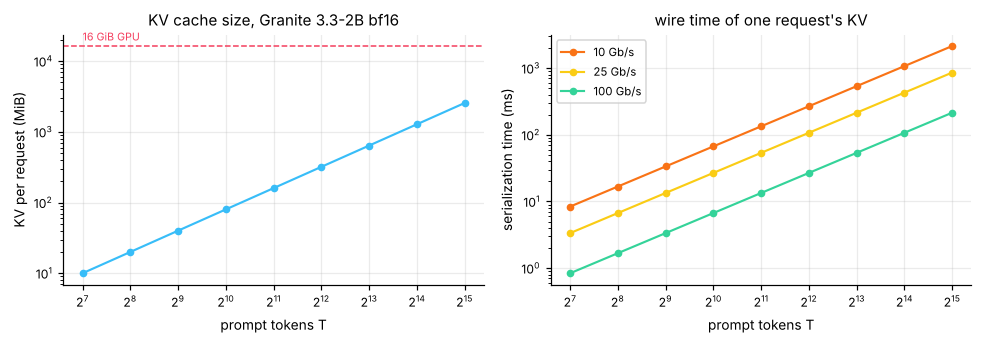

In [4]:
import numpy as np
L, HKV, D, S = 40, 8, 64, 2                      # Granite 3.3-2B, bf16
per_tok = 2 * L * HKV * D * S                    # bytes per token across all layers
T = np.array([128, 256, 512, 1024, 2048, 4096, 8192, 16384, 32768])
req_bytes = per_tok * T
print(f"bytes per token = {per_tok} = {per_tok/1024:.0f} KiB; 2048-token request = {per_tok*2048/2**20:.0f} MiB")
figu, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(T, req_bytes / 2**20, marker="o", color=C["cold"]); ax[0].set_xscale("log", base=2); ax[0].set_yscale("log")
ax[0].set_xlabel("prompt tokens T"); ax[0].set_ylabel("KV per request (MiB)"); ax[0].set_title("KV cache size, Granite 3.3-2B bf16")
ax[0].axhline(16 * 1024, color=C["bad"], ls="--", lw=1); ax[0].text(T[0], 16 * 1024 * 1.2, "16 GiB GPU", color=C["bad"], fontsize=7)
for rate, col in ((10e9, C["hot"]), (25e9, C["gold"]), (100e9, C["ok"])):
    ax[1].plot(T, req_bytes * 8 / rate * 1e3, marker="o", color=col, label=f"{rate/1e9:.0f} Gb/s")
ax[1].set_xscale("log", base=2); ax[1].set_yscale("log"); ax[1].set_xlabel("prompt tokens T"); ax[1].set_ylabel("serialization time (ms)")
ax[1].set_title("wire time of one request's KV"); ax[1].legend()
fig("01_kv_traffic", model=True, caption="arithmetic from the model shape")

## 2. The queueing model (model figure)

1 MiB cold messages: FIFO wait 0.685 ms, priority per message 0.260 ms, per packet 1.07 us


figure -> docs/figures/02_hol_model.png  |  queueing model, Poisson arrivals; not a measurement


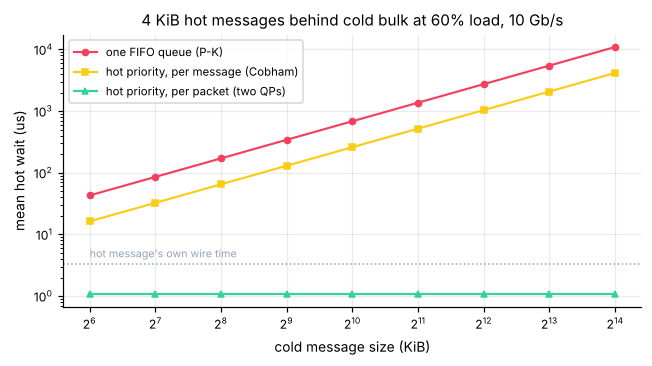

In [5]:
Cbps = 10e9
S_H = 4096 * 8 / Cbps                            # 4 KiB hot message, s
lam_H = 10_000.0                                 # hot messages per second
rho_C = 0.6                                      # cold load
P = 4096                                         # packet payload used for per-packet interleaving
cold_sizes = 2 ** np.arange(16, 25)              # 64 KiB .. 16 MiB
rows_m = []
for sc in cold_sizes:
    S_C = sc * 8 / Cbps
    lam_C = rho_C / S_C
    rho_H = lam_H * S_H
    lamES2 = lam_C * S_C**2 + lam_H * S_H**2
    W_fifo = lamES2 / (2 * (1 - rho_C - rho_H))                       # Pollaczek-Khinchine
    W_prio = (lamES2 / 2) / (1 - rho_H)                                # Cobham, hot has priority, per message
    S_pkt = P * 8 / Cbps; lam_pkt = lam_C * (sc / P)
    W_pkt = ((lam_pkt * S_pkt**2 + lam_H * S_H**2) / 2) / (1 - rho_H)  # residual of a packet instead of a message
    rows_m.append((sc, W_fifo, W_prio, W_pkt))
rows_m = np.array(rows_m)
i1m = int(np.where(cold_sizes == 2**20)[0][0])
print(f"1 MiB cold messages: FIFO wait {rows_m[i1m,1]*1e3:.3f} ms, priority per message {rows_m[i1m,2]*1e3:.3f} ms, per packet {rows_m[i1m,3]*1e6:.2f} us")
figm, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(cold_sizes / 2**10, rows_m[:, 1] * 1e6, marker="o", color=C["bad"], label="one FIFO queue (P-K)")
ax.plot(cold_sizes / 2**10, rows_m[:, 2] * 1e6, marker="s", color=C["gold"], label="hot priority, per message (Cobham)")
ax.plot(cold_sizes / 2**10, rows_m[:, 3] * 1e6, marker="^", color=C["ok"], label="hot priority, per packet (two QPs)")
ax.axhline(S_H * 1e6, color=C["muted"], ls=":", lw=1); ax.text(cold_sizes[0] / 2**10, S_H * 1e6 * 1.3, "hot message's own wire time", fontsize=7, color=C["muted"])
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("cold message size (KiB)"); ax.set_ylabel("mean hot wait (us)")
ax.set_title("4 KiB hot messages behind cold bulk at 60% load, 10 Gb/s"); ax.legend()
fig("02_hol_model", model=True, caption="queueing model, Poisson arrivals; not a measurement")

## 3. Measured: hot p99 with and without a cold stream, one endpoint vs two

In [6]:
HOT_SIZES = [64, 4096]
COLD_SIZES = [256 * 1024, 1 << 20, 4 << 20] if CLUSTER else [256 * 1024, 1 << 20]
raw, rows = [], []
for st in STACKS:
    for single in (False, True):
        tag = "single EP" if single else "dual EP"
        for hot in HOT_SIZES:
            base = st["args"] + ["-m", "hol", "-n", str(N), "-w", str(W), "--hot-size", str(hot), "-W", "8"] + PIN + (["-s"] if single else [])
            d = runner.try_pair(st["tool"], base + ["--no-cold"], env=ENV, **PAIR)
            raw.append(d); rows.append(runner.rows_hol(d, f"{st['label']} | {tag}"))
            for cs in COLD_SIZES:
                d = runner.try_pair(st["tool"], base + ["--cold-size", str(cs)], env=ENV, **PAIR)
                raw.append(d); rows.append(runner.rows_hol(d, f"{st['label']} | {tag}"))
df = pd.DataFrame(rows)
df

,label,single_ep,cold_on,cold_size,hot_size,hot_p50_us,hot_p90_us,hot_p99_us,hot_p999_us,hot_max_us,cold_MBps,n
0,libfabric tcp MSG (local smoke) | dual EP,0,0,1048576,64,16.1935,20.3320,61.4101,85.6898,164.556,0.000,2000
1,libfabric tcp MSG (local smoke) | dual EP,0,1,262144,64,24.0670,33.5900,4130.1088,8000.1152,8035.850,245.202,2000
2,libfabric tcp MSG (local smoke) | dual EP,0,1,1048576,64,14.4270,29.8979,7993.3004,8869.1346,20386.098,601.688,2000
3,libfabric tcp MSG (local smoke) | dual EP,0,0,1048576,4096,16.6375,23.7943,68.1494,445.1824,1559.416,0.000,2000
4,libfabric tcp MSG (local smoke) | dual EP,0,1,262144,4096,19.5555,28.9784,1268.5661,5473.6210,6403.568,283.992,2000
5,libfabric tcp MSG (local smoke) | dual EP,0,1,1048576,4096,28.3435,35.3328,2339.1697,6004.4871,9461.802,662.120,2000
6,libfabric tcp MSG (local smoke) | single EP,1,0,1048576,64,20.5760,25.3361,61.0703,171.9357,1079.736,0.000,2000
7,libfabric tcp MSG (local smoke) | single EP,1,1,262144,64,20.9455,1499.0013,5288.5716,8022.1839,10887.738,1028.772,2000
8,libfabric tcp MSG (local smoke) | single EP,1,1,1048576,64,12.1935,14.7100,55.2580,5675.6030,8336.891,1915.150,2000
9,libfabric tcp MSG (local smoke) | single EP,1,0,1048576,4096,27.8435,35.4436,106.8021,306.4955,1145.337,0.000,2000


wrote /tmp/scuffed-local/fabric/vm_hol_blocking.json


figure -> docs/figures/local/02_hol_measured.png  |  local mode runs the tcp/shm providers; cluster mode runs verbs on SoftRoCE / ConnectX


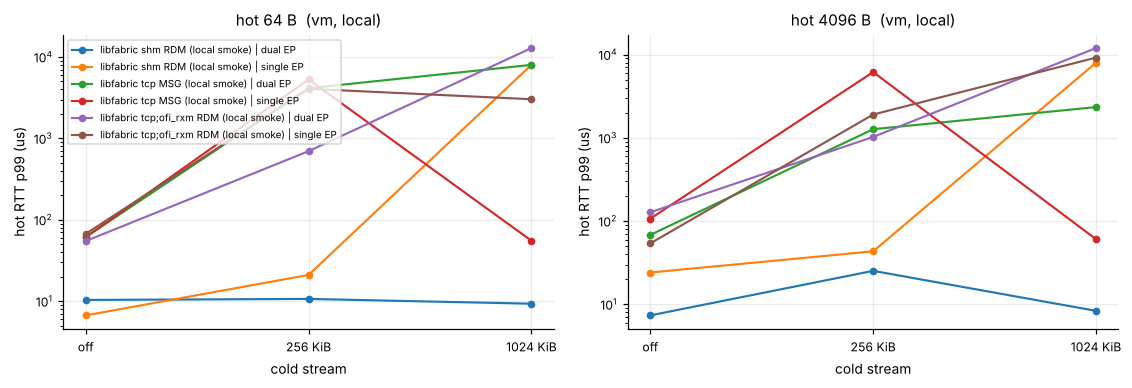

In [7]:
save("hol_blocking", {"rows": rows, "raw": raw})
ok = df[df["error"].isna()] if "error" in df else df
ok = ok.dropna(subset=["hot_p99_us"])
figx, axes = plt.subplots(1, len(HOT_SIZES), figsize=(5.2 * len(HOT_SIZES), 3.6), squeeze=False)
for ax, hot in zip(axes[0], HOT_SIZES):
    sub = ok[ok.hot_size == hot]
    for lab, g in sub.groupby("label"):
        g = g.sort_values(["cold_on", "cold_size"])
        x = ["off" if not c else f"{int(s) >> 10} KiB" for c, s in zip(g.cold_on, g.cold_size.fillna(0))]
        ax.plot(x, g.hot_p99_us, marker="o", label=lab)
    ax.set_yscale("log"); ax.set_xlabel("cold stream"); ax.set_ylabel("hot RTT p99 (us)")
    ax.set_title(f"hot {hot} B  ({HOST}, {MODE})")
axes[0][0].legend(loc="upper left", fontsize=6.5)
fig("02_hol_measured", caption="local mode runs the tcp/shm providers; cluster mode runs verbs on SoftRoCE / ConnectX")

In [8]:
# HOL penalty: loaded p99 / unloaded p99, single vs dual, per stack and cold size
pen = []
for lab, g in ok.groupby("label"):
    for hot, gh in g.groupby("hot_size"):
        un = gh[gh.cold_on == 0].hot_p99_us
        if un.empty: continue
        for _, r in gh[gh.cold_on == 1].iterrows():
            pen.append({"label": lab, "hot_size": hot, "cold_size": r.cold_size, "p99_ratio": r.hot_p99_us / un.iloc[0], "cold_MBps": r.cold_MBps})
pd.DataFrame(pen)

,label,hot_size,cold_size,p99_ratio,cold_MBps
0,libfabric shm RDM (local smoke) | dual EP,64,262144,1.029229,851.537
1,libfabric shm RDM (local smoke) | dual EP,64,1048576,0.898828,907.076
2,libfabric shm RDM (local smoke) | dual EP,4096,262144,3.429609,725.583
3,libfabric shm RDM (local smoke) | dual EP,4096,1048576,1.134113,688.959
4,libfabric shm RDM (local smoke) | single EP,64,262144,3.140847,963.455
5,libfabric shm RDM (local smoke) | single EP,64,1048576,1196.675569,2038.903
6,libfabric shm RDM (local smoke) | single EP,4096,262144,1.795822,1688.752
7,libfabric shm RDM (local smoke) | single EP,4096,1048576,331.955584,1889.751
8,libfabric tcp MSG (local smoke) | dual EP,64,262144,67.254553,245.202
9,libfabric tcp MSG (local smoke) | dual EP,64,1048576,130.162634,601.688


## 4. Re-run of the Update 4 pyverbs benchmark (cluster only)

`benchmarks/benchmark_dual_qp_remote.py` drives the Python pool. With the completion-status fix, a failed
write now raises instead of looking fast. Run it to replace the retracted number.

In [9]:
if CLUSTER:
    out = RESULTS / f"{HOST}_dual_qp_remote_rerun.json"
    print("on the server node (PEER):")
    print(f"  python3 benchmarks/benchmark_dual_qp_remote.py --role server --device {DOMAIN}")
    r = sh(f"python3 benchmarks/benchmark_dual_qp_remote.py --role client --host {PEER_IP} --device {DOMAIN} --output {out}", check=False)
else:
    print("cluster mode only (needs pyverbs and an RDMA device on both nodes)")

cluster mode only (needs pyverbs and an RDMA device on both nodes)
